# Урок 10. Где находится точка, когда поворачивается камера?

[Программа курса](../../README_ru.md)

На столе стоит проволочный треугольник. Камера едет вправо, и треугольник оказывается слева от неё. У проволоки не изменилось ни длины, ни положения на столе. Изменилось место, от которого отсчитывается «вправо». Перед тем как рисовать пиксели, разберёмся с этим отсчётом.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Треугольник в двух окнах

Оба рисунка показывают вид сверху. По горизонтали идёт $x$, по вертикали — глубина $z$. Третья координата, $y$, остаётся в расчёте. Справа начало сетки всегда находится в камере. Оранжевая вершина подвижна, две другие закреплены на общей рамке. «Точка x» сдвигает только вершину и меняет форму. «Объект x» переносит всю рамку и сохраняет её форму. «Камера x» переносит начало отсчёта. «Поворот камеры» разворачивает её оси. Короткая зелёная линия показывает, куда камера смотрит.

В начальном положении справа получается $(1,1,4)$. Теперь пусть «Объект x» и «Камера x» оба увеличатся с 1 до 2. Слева рамка и камера вместе проедут метр. Справа все три вершины останутся на тех же местах. Так выглядит опыт, в котором меняется мир, а кадр останется прежним.

In [2]:
display(demos.geometry_lab(10, "ru"))

## 2. Три числа и три начала отсчёта

В пределах сцены считаем длины в метрах. Оси камеры направлены вправо ($x$), вниз ($y$) и вперёд ($z$). У такого выбора есть удобство: увеличение $y$ позднее будет двигать пиксель вниз по изображению. Тройка $(1,1,4)$ отсчитывает 1 м вправо, 1 м вниз и 4 м вперёд от выбранного начала. Отрицательное $x$ означает столько же метров влево.

Сначала выбранная вершина имеет координаты $p=(1,1,4)$ в системе самой рамки. Начало рамки стоит в точке мира $O=(1,0,0)$. Оси пока параллельны. Положение вершины в мире получается сложением по местам:

$$
P=O+p=(1+1,\;0+1,\;0+4)=(2,1,4).
$$

Ещё одно начало — центр камеры $C=(1,0,0)$ в мире. От него к вершине идёт **смещение** $d$. У смещения есть длина и направление. Оно получается вычитанием начальной точки из конечной:

$$
d=P-C=(2-1,\;1-0,\;4-0)=(1,1,4).
$$

Если камера доедет до $C=(2,0,0)$, по первому месту выйдет $2-2=0$. Вершина прямо впереди по горизонтали, хотя её мировое $x$ всё ещё равно 2. Общий перенос всех точек сохраняет любое смещение между ними: одинаковая прибавка сокращается при вычитании.

In [3]:
p = np.array([1., 1., 4.])
O = np.array([1., 0., 0.])
C = np.array([1., 0., 0.])
P = O + p
print("P =", P, "   P-C =", P - C)
assert np.array_equal((P + [1, 0, 0]) - (C + [1, 0, 0]), P - C)

P = [2. 1. 4.]    P-C = [1. 1. 4.]


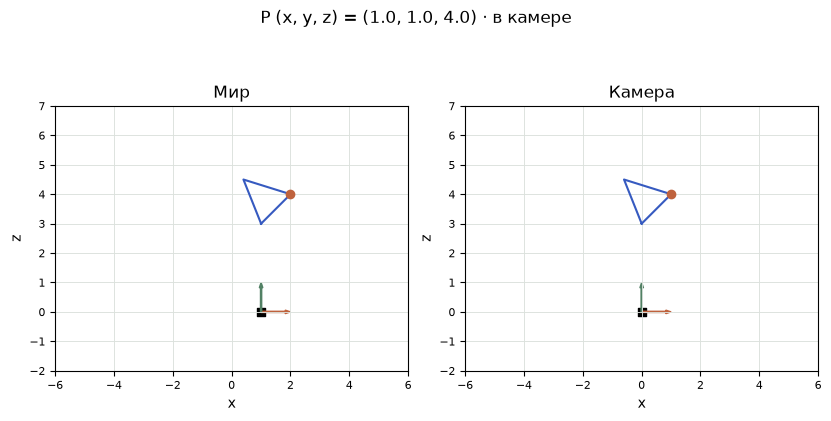

In [4]:
fig = demos.frame_figure("ru")
plt.show()

## 3. Как увидеть одно направление из другого

Оси мира неподвижны. Камера повернулась вокруг своей вертикальной оси на $30^\circ$ вправо. Её единичные направления в координатах мира теперь такие:

$$
r=(0.866,0,-0.5),\quad b=(0,1,0),\quad f=(0.5,0,0.866).
$$

Буквы обозначают правую ось, ось вниз и ось вперёд. «Единичное» означает длину 1: для $f$ сумма квадратов почти равна $0.5^2+0.866^2=1$. Здесь и дальше 0.866 округлено. Длина исходного направления сохраняется при повороте. Числа 0.5 и 0.866 — синус и косинус угла: поперечная и продольная доли единичной стрелки, отклонённой от оси вперёд.

Сколько в $d=(1,1,4)$ движения вдоль новой правой оси? Один метр по мировому $x$ даёт $0.866$ м, метр по мировому $y$ даёт ноль, четыре метра по мировому $z$ дают $4\cdot(-0.5)=-2$ м. В сумме $0.866+0-2=-1.134$ м. Такое сложение попарных произведений называется **скалярным произведением**. Для единичной оси оно измеряет подписанную длину вдоль неё.

Для нижней оси получаем $0\cdot1+1\cdot1+0\cdot4=1$. Для передней — $0.5\cdot1+0\cdot1+0.866\cdot4=3.964$. После поворота вершина слева, ниже и всё ещё впереди. На виде сверху это ровно пересечение $x=-1.134$ и $z=3.964$. Провод, камера и длина смещения остались вполне материальными, поменялись только три линейки.

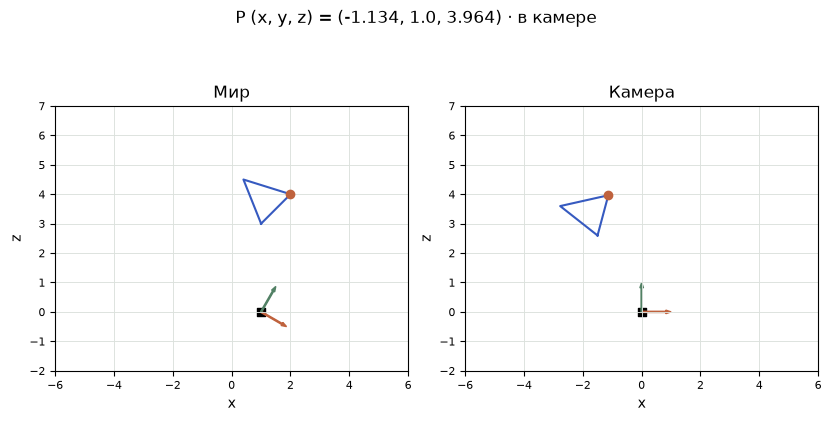

In [5]:
fig = demos.frame_figure("ru", yaw=30)
plt.show()

## 4. Матрица хранит три линейки

Запишем оси столбцами матрицы $B=[r\ b\ f]$. Столбец — три числа сверху вниз. Чтобы получить сразу все три скалярных произведения, нужны эти же оси **строками**. Верхний индекс $\mathsf T$ означает транспонирование: строки и столбцы меняются местами.

$$
p_c=B^{\mathsf T}(P-C)
=\begin{bmatrix}0.866&0&-0.5\\0&1&0\\0.5&0&0.866\end{bmatrix}
\begin{bmatrix}1\\1\\4\end{bmatrix}
\approx\begin{bmatrix}-1.134\\1\\3.964\end{bmatrix}.
$$

Умножение матрицы на столбец — три знакомых расчёта сверху вниз. Для обратного пути складываются три мировые стрелки: $P=C+r\,p_{c,x}+b\,p_{c,y}+f\,p_{c,z}=C+Bp_c$. Транспонирование работает как обратный поворот потому, что оси перпендикулярны и имеют длину 1. Скалярное произведение оси с собой равно 1, с соседней равно 0. Поэтому $B^{\mathsf T}B$ даёт единицы на диагонали и нули вокруг.

Когда вращается сама рамка, появляется ещё один шаг. Матрица $A$ переводит оси объекта в мир. При повороте рамки на $90^\circ$ вокруг $z$ локальная вершина $(1,1,4)$ переходит в $(-1,1,4)$. Перенос $O=(1,0,0)$ даёт мировое $(0,1,4)$. Если сначала прибавить $O$, а затем повернуть сумму, получится $(-1,2,4)$: теперь поворот унесёт и начало рамки. Общая цепочка $p_c=B^{\mathsf T}(O+Ap-C)$ читается изнутри, справа налево.

In [6]:
angle = np.deg2rad(30)
c, s = np.cos(angle), np.sin(angle)
B = np.array([[c,0,s], [0,1,0], [-s,0,c]])
pc = geo.world_to_camera(P, C, B)
print("B.T =\n", B.T, "\np_camera =", pc)
np.testing.assert_allclose(C + B @ pc, P)
np.testing.assert_allclose(B.T @ B, np.eye(3), atol=1e-14)

B.T =
 [[ 0.866  0.    -0.5  ]
 [ 0.     1.     0.   ]
 [ 0.5    0.     0.866]] 
p_camera = [-1.134   1.      3.9641]


In [7]:
A = np.array([[0,-1,0], [1,0,0], [0,0,1]])
print("O+A@p =", O + A @ p, "    A@(O+p) =", A @ (O+p))
print("world distance =", np.linalg.norm(P-C), "  camera distance =", np.linalg.norm(pc))

O+A@p = [0. 1. 4.]     A@(O+p) = [-1.  2.  4.]
world distance = 4.242640687119285   camera distance = 4.242640687119285


## 5. Что останется на рисунке

**Опыт.** Пусть камера пока смотрит прямо. Что случится с относительной координатой, если камера проедет метр вправо, а вершина проедет два?

<details>
<summary>Разбор</summary>

Новый мировой $x$ вершины равен $2+2=4$, у камеры $1+1=2$. Справа появится $4-2=2$ вместо 1. Остальные координаты останутся 1 и 4. Правая проекция выросла на разность перемещений: $2-1=1$ м.

</details>

**Ещё один ракурс.** При каком повороте начальный вектор $(1,1,4)$ окажется точно по центру по горизонтали?

<details>
<summary>Разбор</summary>

Для нового правого компонента нужно $1\cos\theta-4\sin\theta=0$. Делим на $4\cos\theta$ и получаем $\tan\theta=1/4$. Тангенс — отношение поперечного катета к продольному. Обратная операция возвращает угол, примерно $14.04^\circ$. При ближайшем целом значении $14^\circ$ остаётся около $0.003$ м. Вертикальная координата всё ещё 1, поэтому это центр только по горизонтали.

</details>